In [4]:
import pandas as pd
!pip install scikit-learn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pytz


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
df = pd.read_csv(r"C:\Users\Ezhilarasi\Downloads\online_retail.csv")
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [6]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2022-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2022-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
(df.isnull().sum()/ len(df))*100

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

<Axes: >

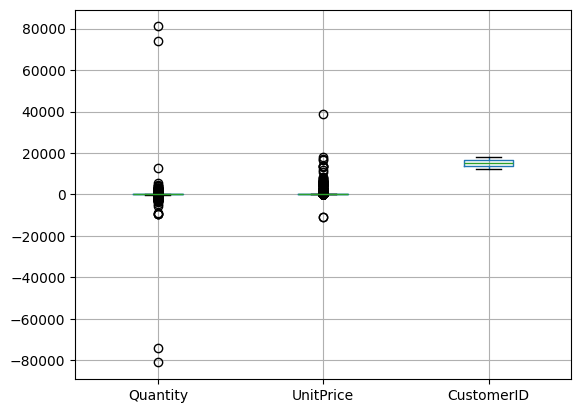

In [9]:
df.boxplot()

In [10]:
def treat_outliers_iqr(df,variable):
    q1=df[variable].quantile(0.25)
    q3=df[variable].quantile(0.75)
    iqr=q1-q3
    ll=q1-1.5*iqr
    up=q3-1.5*iqr
    df=df[(df[variable]>=ll)&(df[variable]<=up)]
    return df
def remove_outlier(df):
    for col in df.select_dtypes(include='number').columns:
        df= treat_outliers_iqr(df,col)
        return df

In [11]:
for i in df.select_dtypes(include='O').columns:
    if df[i].isnull().sum()>0:
        print(i)
        df[i].fillna(df[i].mode()[0],inplace=True)

Description


C:\Users\Ezhilarasi\AppData\Local\Temp\ipykernel_444\3096230428.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[i].fillna(df[i].mode()[0],inplace=True)


In [12]:
# Step 2: Data Preprocessing

# 1. Remove rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])

# 2. Exclude cancelled invoices (InvoiceNo starting with 'C')
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# 3. Remove negative or zero quantities and prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Reset index after cleaning
df = df.reset_index(drop=True)

df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2022-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2022-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom


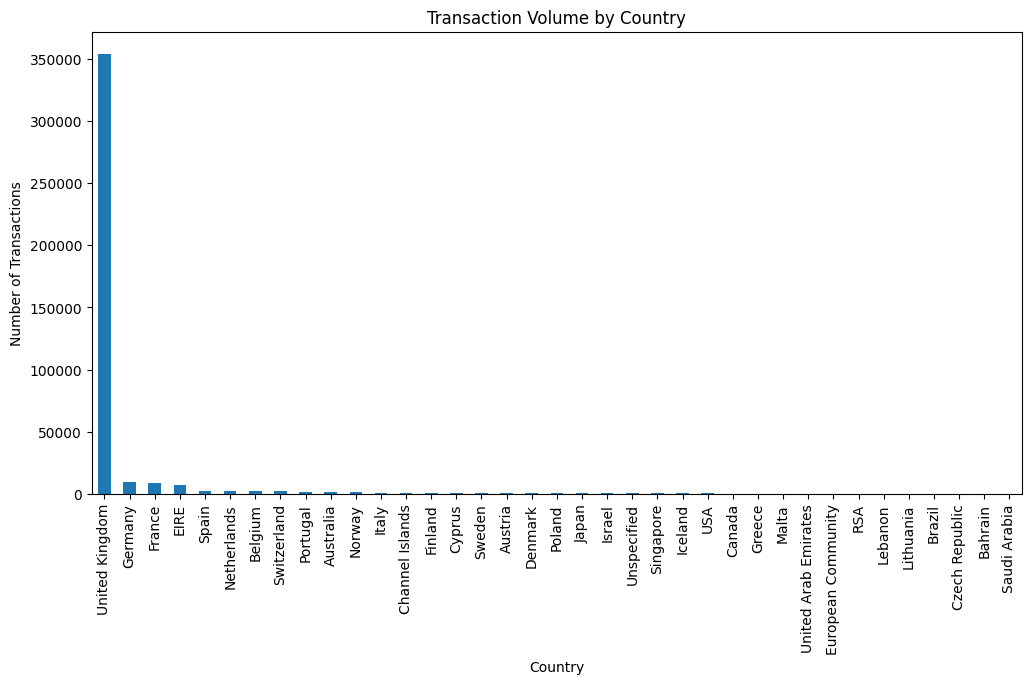

In [13]:
#Transaction Volume by Country
plt.figure(figsize=(12,6))
df['Country'].value_counts().sort_values(ascending=False).plot(kind='bar')
plt.title("Transaction Volume by Country")
plt.xlabel("Country")
plt.ylabel("Number of Transactions")
plt.show()


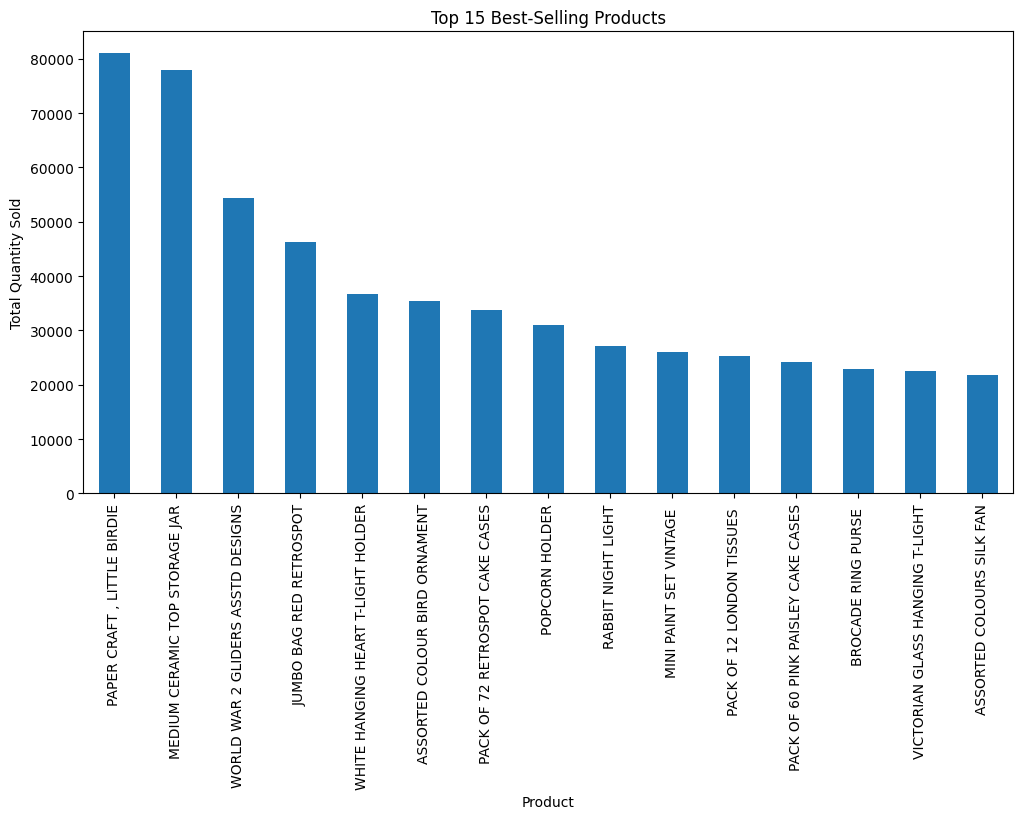

In [14]:
#Top-Selling Products
top_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(15)

plt.figure(figsize=(12,6))
top_products.plot(kind='bar')
plt.title("Top 15 Best-Selling Products")
plt.xlabel("Product")
plt.ylabel("Total Quantity Sold")
plt.show()


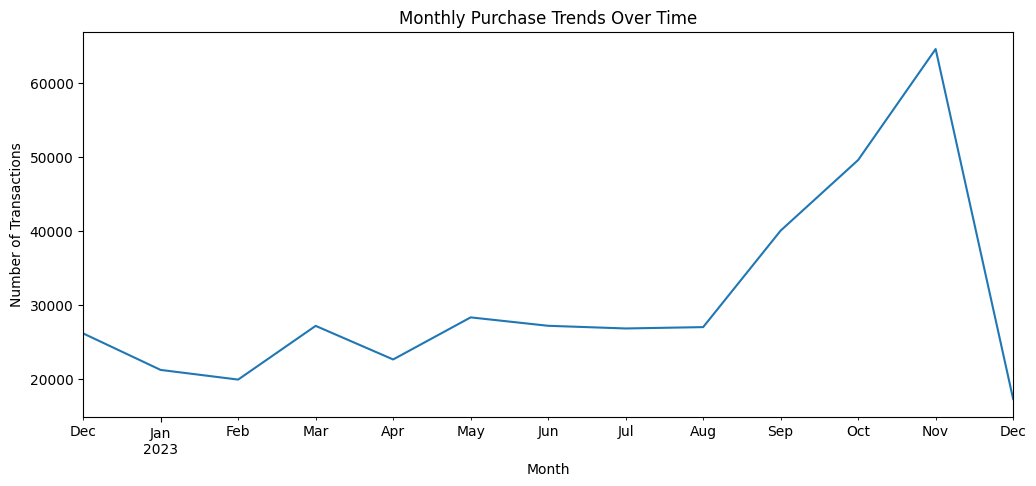

In [15]:
#Purchase Trends Over Time
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

#Monthly Trend
monthly_sales = df.groupby('InvoiceMonth')['InvoiceNo'].count()

plt.figure(figsize=(12,5))
monthly_sales.plot()
plt.title("Monthly Purchase Trends Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.show()


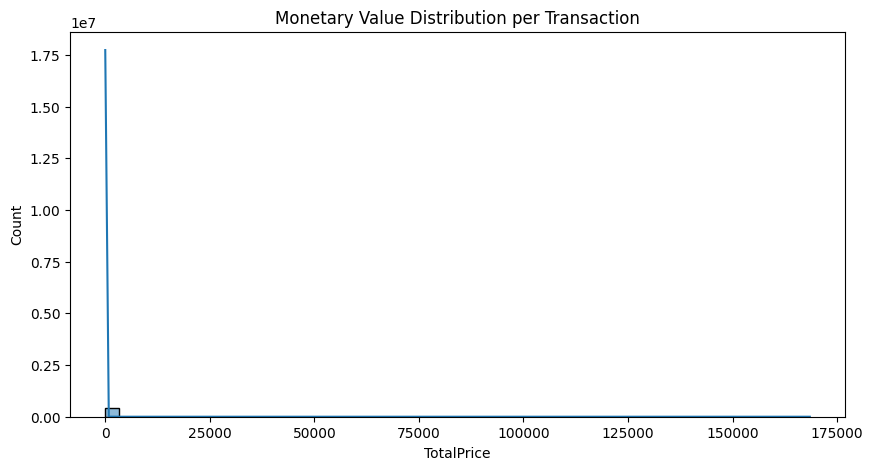

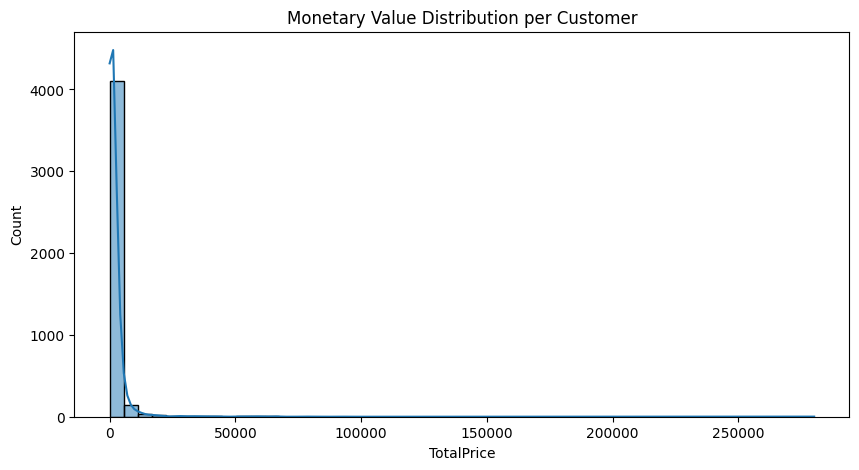

In [16]:
#4️ Monetary Distribution per Transaction & Customer
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Per Transaction
plt.figure(figsize=(10,5))
sns.histplot(df['TotalPrice'], bins=50, kde=True)
plt.title("Monetary Value Distribution per Transaction")
plt.show()

# Per Customer
customer_value = df.groupby('CustomerID')['TotalPrice'].sum()

plt.figure(figsize=(10,5))
sns.histplot(customer_value, bins=50, kde=True)
plt.title("Monetary Value Distribution per Customer")
plt.show()



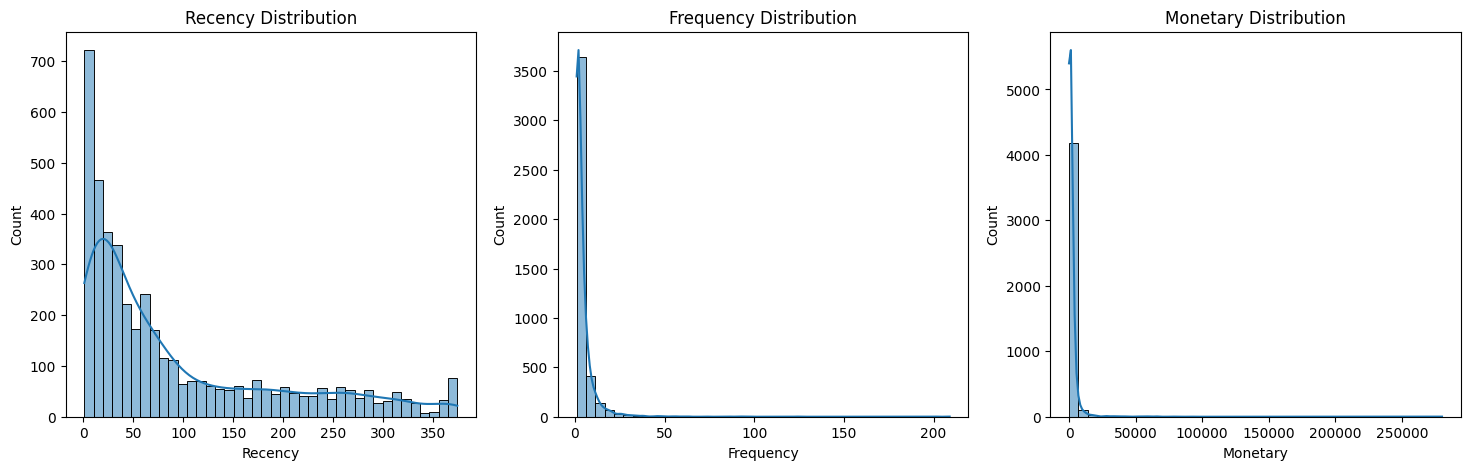

In [17]:
# 5️ RFM Distributions
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

# Plot distributions

fig, axes = plt.subplots(1, 3, figsize=(18,5))

sns.histplot(rfm['Recency'], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Recency Distribution")

sns.histplot(rfm['Frequency'], bins=40, kde=True, ax=axes[1])
axes[1].set_title("Frequency Distribution")

sns.histplot(rfm['Monetary'], bins=40, kde=True, ax=axes[2])
axes[2].set_title("Monetary Distribution")

plt.show()


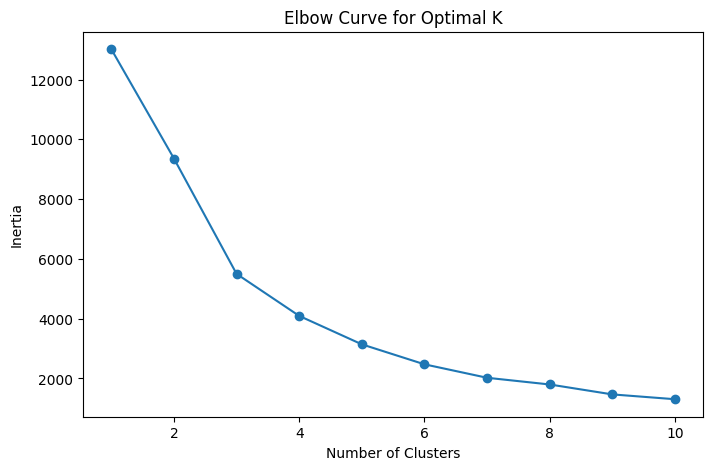

In [18]:
# Elbow Curve for K-Means Cluster Selection
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

#Elbow plot:
inertia = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K, inertia, marker='o')
plt.title("Elbow Curve for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()


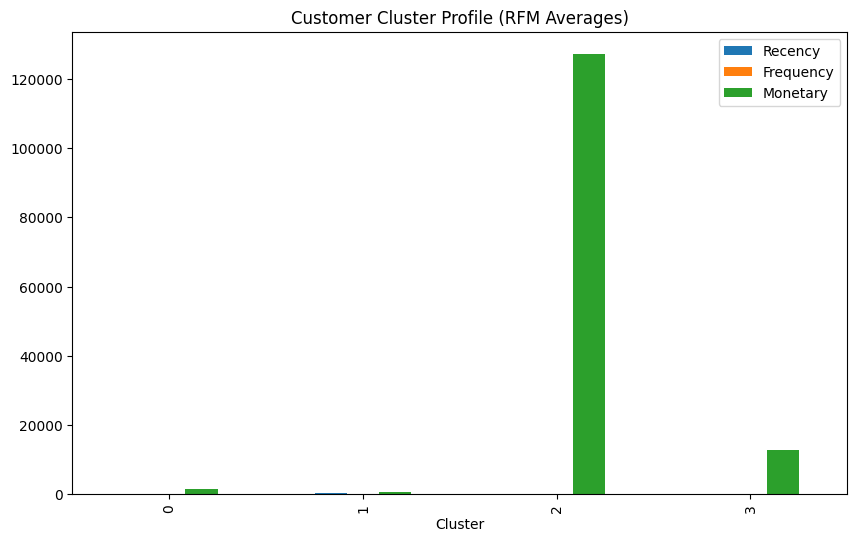

In [ ]:
#Customer Cluster Profiles

#ssume K=4 (after elbow test): Cluster 0 — High-value customers,Cluster 1 — Regular customers,Cluster 2 — At-risk customers,Cluster 3 — Occasional or low-value customers

kmeans = KMeans(n_clusters=4, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

#Cluster summary

cluster_profile = rfm.groupby('Cluster').mean()
cluster_profile

#Visualize

cluster_profile.plot(kind='bar', figsize=(10,6))
plt.title("Customer Cluster Profile (RFM Averages)")
plt.show()


In [20]:
#Clustering Methodology
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,     # Recency
    'InvoiceNo': 'nunique',                                     # Frequency
    'TotalPrice': 'sum'                                         # Monetary
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']
    

In [21]:
#Standardize the RFM Values
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()         
rfm_scaled = scaler.fit_transform(rfm)


In [22]:
#Determine Best Number of Clusters

from sklearn.cluster import KMeans

inertia = []
K = range(1,11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

kmeans = KMeans(n_clusters=4, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)


In [23]:
rfm.groupby('Cluster').mean()

def label_cluster(row):
    r, f, m = row['Recency'], row['Frequency'], row['Monetary']

    if (r < rfm['Recency'].median()) and (f > rfm['Frequency'].median()) and (m > rfm['Monetary'].median()):
        return "High-Value"

    if (f >= rfm['Frequency'].median()) and (m >= rfm['Monetary'].median()):
        return "Regular"

    if (f < rfm['Frequency'].median()) and (m < rfm['Monetary'].median()) and (r > rfm['Recency'].median()):
        return "Occasional"

    return "At-Risk"

rfm['Segment'] = rfm.apply(label_cluster, axis=1)



In [24]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(rfm_scaled)


,n_clusters,4
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [ ]:
import joblib

joblib.dump(kmeans, 'rfm_kmeans_model.pkl')
joblib.dump(scaler, 'rfm_scaler.pkl')


['rfm_scaler.pkl']

In [ ]:
import joblib
sim = joblib.load("similarity_df.pkl")

print("Index sample:", list(sim.index[:5]))
print("Column sample:", list(sim.columns[:5]))


Index sample: ['10 COLOUR SPACEBOY PEN', '12 COLOURED PARTY BALLOONS', '12 DAISY PEGS IN WOOD BOX', '12 EGG HOUSE PAINTED WOOD', '12 HANGING EGGS HAND PAINTED']
Column sample: ['10 COLOUR SPACEBOY PEN', '12 COLOURED PARTY BALLOONS', '12 DAISY PEGS IN WOOD BOX', '12 EGG HOUSE PAINTED WOOD', '12 HANGING EGGS HAND PAINTED']
